# 06 · Risultati

## 1. Domanda di ricerca

> Quanto cambia la valutazione di una strategia di market making passivo quando le esecuzioni stimate con regole L2 vengono confrontate con un replay order-level che considera la posizione nella coda?

**Domanda secondaria.** Il filtro di bassa volatilità riduce le perdite e il rischio di inventario rispetto alla strategia sempre attiva?

## 2. Protocollo sperimentale

La stessa strategia, con gli stessi parametri, è simulata con quattro modelli di esecuzione: le regole L2 `touch`, `price-through` e `cross` e il replay della coda FIFO (solo per i dati order-level). Le sessioni sono divise in calibrazione, validazione e test in ordine cronologico; il test non viene mai usato per scegliere parametri o varianti. Per ITCH e Hyperliquid la validazione è di una sola sessione: la selezione dei parametri può essere influenzata dal caso.

**Intervalli di confidenza.** I titoli della stessa giornata non sono osservazioni indipendenti: l'intervallo principale ricampiona **giornate (o ore) intere** con tutti i loro titoli (bootstrap per sessione, seme fisso). Con poche sessioni indipendenti (5 giornate ITCH, 4 ore Hyperliquid) anche questo intervallo è un'approssimazione e può sottostimare l'incertezza.

**Costi.** Le tariffe usate (Nasdaq: rebate di 0,20 cent/azione al maker, 0,30 cent/azione al taker; Hyperliquid: 1,5 bps maker e 4,5 bps taker al livello base, −0,3 e 2,4 bps al livello alto) sono **ipotesi sperimentali indicative**, da verificare sulle tabelle ufficiali del periodo analizzato.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti esplorative
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

from market_making_tesi.evaluation import grouped_bootstrap_ci, sample_counts
NET = {"fi2010": "final_equity", "itch": "net_nasdaq_base", "hyperliquid": "net_tier0"}
UNIT = {"fi2010": "unità normalizzate per titolo-giorno", "itch": "USD per titolo-giorno", "hyperliquid": "USD per ora"}
q_itch = test[(test.dataset == "itch") & (test.model == "queue")]
q_hl = test[(test.dataset == "hyperliquid") & (test.model == "queue")]
m_itch = grouped_bootstrap_ci(q_itch.net_nasdaq_base, q_itch.session)
m_hl = grouped_bootstrap_ci(q_hl.net_tier0, q_hl.session)
touch_itch = test[(test.dataset == "itch") & (test.model == "touch")].net_nasdaq_base.mean()
R.show_box("Risposta in breve", [
    f"Su Nasdaq ITCH, con il replay della coda, la strategia ha un P&L netto medio di {it(m_itch[0], 2)} USD per titolo-giorno "
    f"(IC 95% per giornata {it(m_itch[1], 2)}; {it(m_itch[2], 2)}); con `touch` sembrerebbe guadagnare {it(touch_itch, 2)} USD.",
    f"Su Hyperliquid il P&L netto con la coda è {it(m_hl[0], 2)} USD per ora (IC 95% {it(m_hl[1], 2)}; {it(m_hl[2], 2)}).",
    "La valutazione cambia di segno passando dalle regole L2 al replay della coda: il modello di esecuzione determina il risultato.",
])

> **Risposta in breve**
>
> - Su Nasdaq ITCH, con il replay della coda, la strategia ha un P&L netto medio di -540,59 USD per titolo-giorno (IC 95% per giornata -580,70; -500,47); con `touch` sembrerebbe guadagnare 139.086,43 USD.
> - Su Hyperliquid il P&L netto con la coda è -47,28 USD per ora (IC 95% -56,71; -34,16).
> - La valutazione cambia di segno passando dalle regole L2 al replay della coda: il modello di esecuzione determina il risultato.

## 3. Campione di test realmente disponibile

In [2]:
rows = []
for name in NET:
    g = test[(test.dataset == name) & (test.model == test[test.dataset == name].model.iloc[0])]
    c = sample_counts(g)
    rows.append({"dataset": R.DATASET_LABELS[name], "sessioni indipendenti": c["n_sessioni_indipendenti"],
                 "unità": R.SESSION_UNITS[name], "titoli per sessione": g.symbol.nunique(),
                 "titolo-sessioni": c["n_titolo_sessioni"], "misura del P&L": UNIT[name]})
display(pd.DataFrame(rows).set_index("dataset"))
display(Markdown("I 35 titolo-giorni FI-2010 e i 15 titolo-giorni ITCH **non** sono giornate indipendenti: "
                 "le giornate indipendenti sono 7 e 5."))
summary_tables = []
for name in NET:
    table = R.overview_table(test, name, NET[name], 4 if name == "fi2010" else 2)
    table = table.rename(columns={table.columns[0]: "sessioni indipendenti"})
    table.insert(0, "misura del P&L", UNIT[name])
    table.index = pd.MultiIndex.from_product([[R.DATASET_LABELS[name]], table.index], names=["dataset", "modello"])
    summary_tables.append(table)
pd.concat(summary_tables).to_csv(ROOT / "results" / "tabella_riepilogo.csv")

,sessioni indipendenti,unità,titoli per sessione,titolo-sessioni,misura del P&L
dataset,,,,,
FI-2010,7,giornate,5,35,unità normalizzate per titolo-giorno
Nasdaq ITCH,5,giornate,3,15,USD per titolo-giorno
Hyperliquid BTC,4,ore,1,4,USD per ora


I 35 titolo-giorni FI-2010 e i 15 titolo-giorni ITCH **non** sono giornate indipendenti: le giornate indipendenti sono 7 e 5.

## 4. Confronto dei modelli di esecuzione

Per ITCH e Hyperliquid si conosce il risultato del replay della coda: si può misurare di quante volte ogni regola L2 sovrastima le esecuzioni e di quanto sposta il P&L lordo.

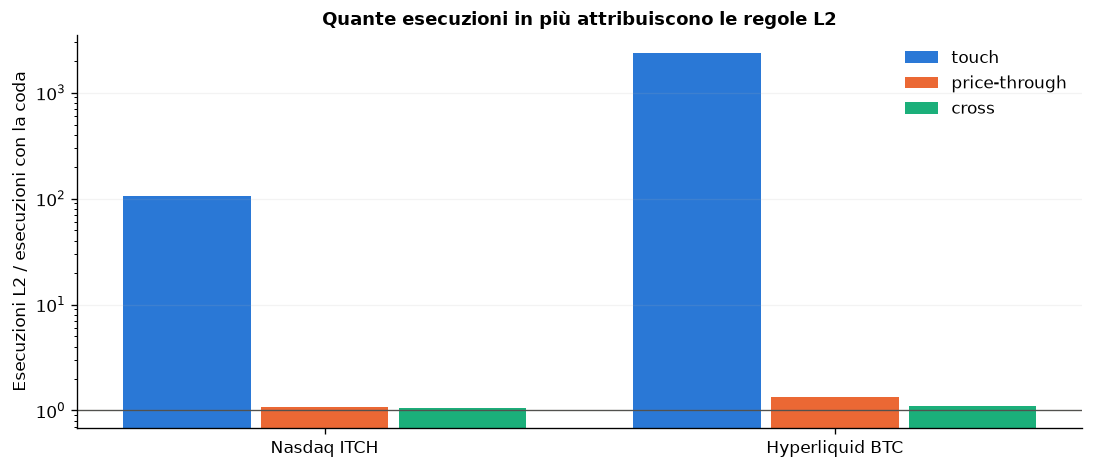

*Figura.* Rapporto mediano tra le esecuzioni di ogni regola L2 e quelle del replay della coda (1 = stesso numero). `touch` sovrastima le esecuzioni di due o tre ordini di grandezza; `price-through` e `cross` sono vicine nel numero ma sbagliano comunque il P&L, perché non sanno quali esecuzioni sarebbero toccate alla quota. *Limite:* anche il replay della coda è un modello: non considera gli ordini nascosti né l'impatto della quota sul mercato.

In [3]:
bias_rows = []
for name in ["itch", "hyperliquid"]:
    ratios = R.fill_bias(test, name)
    pnl = test[test.dataset == name].pivot_table(index=["session", "symbol"], columns="model", values="final_equity")
    for model in ["touch", "price-through", "cross"]:
        bias_rows.append({"dataset": R.DATASET_LABELS[name], "regola": R.LABELS[model],
                          "esecuzioni rispetto alla coda": ratios[model].median(),
                          "differenza media di P&L lordo dalla coda": (pnl[model] - pnl["queue"]).mean()})
bias = pd.DataFrame(bias_rows)
display(bias.set_index(["dataset", "regola"]).style.format({"esecuzioni rispetto alla coda": "{:,.1f}×",
                                                             "differenza media di P&L lordo dalla coda": "{:+,.2f}"}))
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
names = bias.dataset.unique()
x = np.arange(len(names))
for i, model in enumerate(["touch", "price-through", "cross"]):
    vals = bias[bias.regola == R.LABELS[model]].set_index("dataset").loc[names, "esecuzioni rispetto alla coda"]
    ax.bar(x + (i - 1) * 0.27, vals, 0.25, color=R.COLORS[model], label=R.LABELS[model])
ax.axhline(1, color=R.INK, linewidth=0.8)
ax.set_xticks(x, names)
ax.set(yscale="log", ylabel="Esecuzioni L2 / esecuzioni con la coda", title="Quante esecuzioni in più attribuiscono le regole L2")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "bias_esecuzione.png", dpi=180, bbox_inches="tight")
plt.show()
R.caption("Rapporto mediano tra le esecuzioni di ogni regola L2 e quelle del replay della coda (1 = stesso numero).",
          "`touch` sovrastima le esecuzioni di due o tre ordini di grandezza; `price-through` e `cross` sono vicine nel "
          "numero ma sbagliano comunque il P&L, perché non sanno quali esecuzioni sarebbero toccate alla quota.",
          "anche il replay della coda è un modello: non considera gli ordini nascosti né l'impatto della quota sul mercato.")

## 5. Risultato principale: Nasdaq ITCH

In [4]:
display(R.overview_table(test, "itch", NET["itch"], 2))
parts = []
for name, fee in [("itch", "fees_nasdaq_base"), ("hyperliquid", "fees_tier0")]:
    table = R.decomposition_table(R.decomposition(test, name, fee), 2).loc[["coda FIFO"]]
    table.index = [R.DATASET_LABELS[name]]
    parts.append(table)
display(Markdown("**Scomposizione del P&L con la coda FIFO** (ITCH: USD per titolo-giorno; Hyperliquid: USD per ora)"))
display(pd.concat(parts))
display(Markdown("**Come leggerlo.** Su ITCH pesano soprattutto la selezione avversa (il prezzo si muove contro dopo "
                 "l'esecuzione) e il costo per chiudere le coppie rimaste a metà; su Hyperliquid le commissioni."))

,giornate indipendenti,titolo-sessioni,P&L netto medio (IC 95% per sessione),IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,5,15,"139.086,43 (131.220,13; 145.444,17)","(121.853,75; 158.196,63)",100%,"99,7%",1.663.163.114
price-through,5,15,"-392,79 (-663,31; 29,01)","(-672,33; 81,29)",7%,"68,3%",34.547.647
cross,5,15,"-1.305,11 (-1.525,02; -1.085,21)","(-1.814,21; -876,74)",0%,"66,6%",28.420.777
coda FIFO,5,15,"-540,59 (-580,70; -500,47)","(-659,64; -434,79)",0%,"49,7%",15.837.570


**Scomposizione del P&L con la coda FIFO** (ITCH: USD per titolo-giorno; Hyperliquid: USD per ora)

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
Nasdaq ITCH,"437,02","-268,61","-738,69","-570,29","29,70","-540,59"
Hyperliquid BTC,"0,59","-1,27","-2,57","-3,25","-44,04","-47,28"


**Come leggerlo.** Su ITCH pesano soprattutto la selezione avversa (il prezzo si muove contro dopo l'esecuzione) e il costo per chiudere le coppie rimaste a metà; su Hyperliquid le commissioni.

## 6. Robustezza: FI-2010 e Hyperliquid

FI-2010 non ha la coda degli ordini: le sue tabelle confrontano solo regole L2, in **unità normalizzate**. Hyperliquid è una verifica su un secondo mercato, con i limiti descritti nel notebook 05.

In [5]:
display(Markdown("**FI-2010** (P&L in unità normalizzate per titolo-giorno, senza costi)"))
display(R.overview_table(test, "fi2010", NET["fi2010"], 4).rename(
    columns={"P&L netto medio (IC 95% per sessione)": "P&L medio, unità normalizzate (IC 95% per giornata)"}))
display(Markdown("**Hyperliquid** (P&L netto per ora, USD, commissioni base)"))
display(R.overview_table(test, "hyperliquid", NET["hyperliquid"], 2))
hl_touch = test[(test.dataset == "hyperliquid") & (test.model == "touch")]
display(Markdown(f"Su Hyperliquid `touch` è negativo al netto ({it(hl_touch.net_tier0.mean(), 2)} USD per ora) "
                 "perché conta così tante esecuzioni che le commissioni superano lo spread; al lordo sarebbe molto positivo."))

**FI-2010** (P&L in unità normalizzate per titolo-giorno, senza costi)

,giornate indipendenti,titolo-sessioni,"P&L medio, unità normalizzate (IC 95% per giornata)",IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,7,35,"0,3715 (0,2641; 0,5022)","(0,2435; 0,5294)",100%,"97,7%",456
price-through,7,35,"-0,0044 (-0,0057; -0,0029)","(-0,0073; -0,0018)",20%,"69,3%","29,86"
cross,7,35,"-0,0141 (-0,0159; -0,0118)","(-0,0184; -0,0102)",0%,"49,1%","18,12"


**Hyperliquid** (P&L netto per ora, USD, commissioni base)

,ore indipendenti,titolo-sessioni,P&L netto medio (IC 95% per sessione),IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,4,4,"-93.878,43 (-120.920,76; -66.836,10)","(-120.920,76; -66.836,10)",0%,"100,0%",650.804.300
price-through,4,4,"-222,89 (-246,82; -198,96)","(-246,82; -198,96)",0%,"51,8%",656.341
cross,4,4,"-192,78 (-229,34; -160,61)","(-229,34; -160,61)",0%,"44,7%",564.295
coda FIFO,4,4,"-47,28 (-56,71; -34,16)","(-56,71; -34,16)",0%,"21,3%",162.407


Su Hyperliquid `touch` è negativo al netto (-93.878,43 USD per ora) perché conta così tante esecuzioni che le commissioni superano lo spread; al lordo sarebbe molto positivo.

## 7. Effetto del filtro di volatilità

Confronto sessione per sessione tra la strategia con filtro e la stessa strategia sempre attiva, con il modello di riferimento di ogni dataset. Oltre al P&L si guarda il rischio di inventario: drawdown massimo e numero di liquidazioni a mercato.

In [6]:
filters = []
for name, ref in [("fi2010", "price-through"), ("itch", "queue"), ("hyperliquid", "queue")]:
    eff = R.filter_effect(test, ablation, name, NET[name])
    row = R.filter_table(eff, 4 if name == "fi2010" else 2).loc[[R.LABELS[ref]]]
    on = test[(test.dataset == name) & (test.model == ref)]
    off = ablation[(ablation.dataset == name) & (ablation.model == ref)]
    d = 6 if name == "fi2010" else 2
    row["drawdown medio con filtro / senza"] = f"{it(on.max_drawdown.mean(), d)} / {it(off.max_drawdown.mean(), d)}"
    row["liquidazioni a mercato con filtro / senza"] = f"{it(on.taker_fills.mean())} / {it(off.taker_fills.mean())}"
    row.index = [R.DATASET_LABELS[name]]
    filters.append(row)
    eff.loc[[R.LABELS[ref]]].assign(dataset=R.DATASET_LABELS[name]).to_csv(
        ROOT / "results" / "tabella_filtro_volatilita.csv", mode="a" if len(filters) > 1 else "w", header=len(filters) == 1)
display(pd.concat(filters))
verdicts = []
for name, ref in [("fi2010", "price-through"), ("itch", "queue"), ("hyperliquid", "queue")]:
    r = R.filter_effect(test, ablation, name, NET[name]).loc[R.LABELS[ref]]
    word = "migliora" if r["IC95 basso"] > 0 else "peggiora" if r["IC95 alto"] < 0 else "non cambia in modo significativo"
    verdicts.append(f"su {R.DATASET_LABELS[name]} {word} il P&L")
display(Markdown(f"**Come leggerlo.** Il filtro {', '.join(verdicts)}. In nessun caso rende la strategia profittevole."))

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera,drawdown medio con filtro / senza,liquidazioni a mercato con filtro / senza
FI-2010,"-0,0044","-0,0026","-0,0019 (-0,0031; -0,0006)",23%,85%,"0,007901 / 0,007170",37 / 29
Nasdaq ITCH,"-540,59","-691,75","151,17 (61,79; 295,65)",80%,71%,"588,55 / 783,61",392 / 463
Hyperliquid BTC,"-47,28","-122,34","75,05 (22,26; 127,84)",100%,32%,"3,34 / 10,78",118 / 292


**Come leggerlo.** Il filtro su FI-2010 peggiora il P&L, su Nasdaq ITCH migliora il P&L, su Hyperliquid BTC migliora il P&L. In nessun caso rende la strategia profittevole.

## 8. Effetto della latenza

La latenza cambia le esecuzioni e va simulata: la quota entra nel mercato e viene cancellata con ritardo, e se all'attivazione attraverserebbe il book viene rifiutata (*post-only*). Su Hyperliquid la latenza è in eventi, perché i dati non hanno orari.

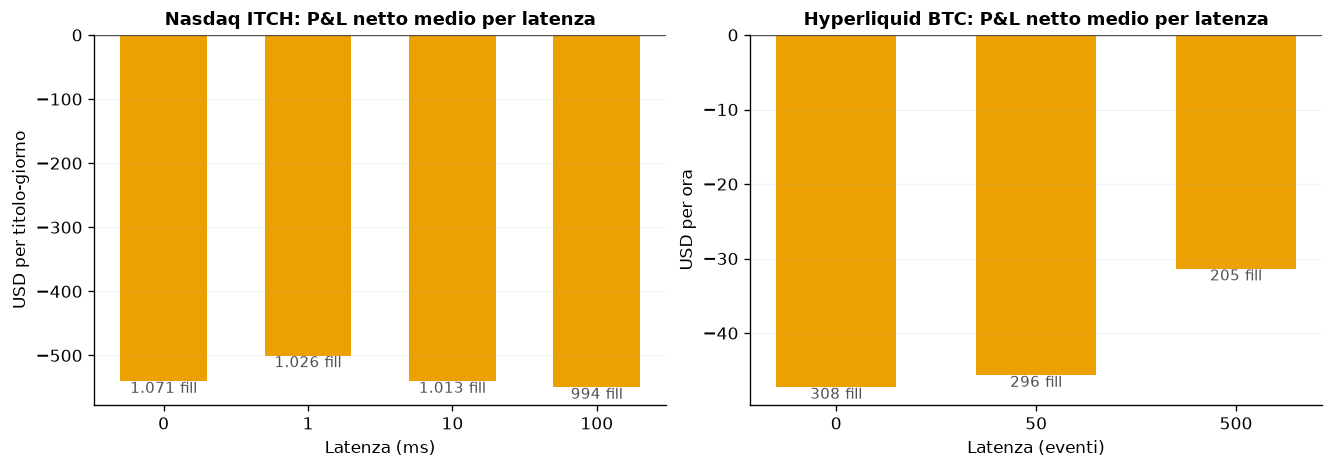

*Figura.* P&L netto medio della strategia base con la coda FIFO al crescere della latenza. Su ITCH il risultato resta tra -549,89 e -500,45 USD; su Hyperliquid passa da -47,28 a -31,40 USD perché con più latenza le esecuzioni scendono da 308 a 205 e si pagano meno commissioni. Il P&L netto resta negativo a ogni livello. *Limite:* la latenza è modellata come un ritardo costante; i market maker reali operano in microsecondi (Hasbrouck e Saar, 2013; Budish, Cramton e Shim, 2015).

In [7]:
stress = R.load(ROOT, "stress")
ranges = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, name, col, unit, fee, scale in [(axes[0], "itch", "param_latency_ns", "ms", "net_nasdaq_base", 1e6),
                                         (axes[1], "hyperliquid", "param_latency_events", "eventi", "net_tier0", 1)]:
    agg = stress[stress.dataset == name].groupby(col).agg(netto=(fee, "mean"), fill=("maker_fills", "mean"))
    ranges[name] = (agg.netto.iloc[0], agg.netto.min(), agg.netto.max(), agg.fill.iloc[0], agg.fill.iloc[-1])
    labels = [it(v / scale, 0 if v == 0 or v / scale >= 1 else 1) for v in agg.index]
    ax.bar(labels, agg.netto, color=R.COLORS["queue"], width=0.6)
    for k, (v, f) in enumerate(zip(agg.netto, agg.fill)):
        ax.text(k, v, f"{it(f)} fill", ha="center", va="top" if v < 0 else "bottom", color=R.INK, fontsize=9)
    ax.axhline(0, color=R.INK, linewidth=0.8)
    ax.set(title=f"{R.DATASET_LABELS[name]}: P&L netto medio per latenza", xlabel=f"Latenza ({unit})",
           ylabel="USD per titolo-giorno" if name == "itch" else "USD per ora")
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "stress_latenza.png", dpi=180, bbox_inches="tight")
plt.show()
ri, rh = ranges["itch"], ranges["hyperliquid"]
R.caption("P&L netto medio della strategia base con la coda FIFO al crescere della latenza.",
          f"Su ITCH il risultato resta tra {it(ri[1], 2)} e {it(ri[2], 2)} USD; su Hyperliquid passa da {it(rh[0], 2)} a "
          f"{it(rh[2], 2)} USD perché con più latenza le esecuzioni scendono da {it(rh[3])} a {it(rh[4])} e si pagano meno "
          "commissioni. Il P&L netto resta negativo a ogni livello.",
          "la latenza è modellata come un ritardo costante; i market maker reali operano in microsecondi "
          "(Hasbrouck e Saar, 2013; Budish, Cramton e Shim, 2015).")

## 9. Varianti esplorative

Le varianti (inventory skew, filtro di imbalance e la loro combinazione) sono state **aggiunte dopo** aver osservato le perdite della strategia base: i loro parametri sono scelti in validazione, ma l'idea stessa di provarle dipende dai risultati. Sono un'analisi esplorativa, non il risultato principale. Per FI-2010 il riferimento è `price-through`: un risultato positivo in unità normalizzate **non** dimostra una profittabilità reale.

P&L netto medio (IC 95%)  \
                variante                                          
Nasdaq ITCH     base                 -540,59 (-580,70; -500,47)   
                inventory skew        -144,48 (-238,66; -69,19)   
                filtro di imbalance  -259,19 (-296,80; -207,90)   
                skew + imbalance       -70,75 (-121,00; -23,00)   
Hyperliquid BTC base                    -47,28 (-56,71; -34,16)   
                inventory skew          -39,33 (-44,33; -31,14)   
                filtro di imbalance        -6,40 (-9,87; -3,92)   
                skew + imbalance           -5,64 (-8,43; -3,58)   
FI-2010         base                 -0,0044 (-0,0057; -0,0029)   
                inventory skew          0,0011 (0,0002; 0,0021)   
                filtro di imbalance  -0,0183 (-0,0195; -0,0167)   
                skew + imbalance        0,0193 (0,0171; 0,0212)   

                                    sessioni positive  \
                variante                                
Nasdaq ITCH     base                               0%   
                inventory skew                    13%   
                filtro di imbalance                0%   
                skew + imbalance                  13%   
Hyperliquid BTC base                               0%   
                inventory skew                     0%   
                filtro di imbalance                0%   
                skew + imbalance                   0%   
FI-2010         base                              20%   
                inventory skew                    54%   
                filtro di imbalance                0%   
                skew + imbalance                 100%   

                                    differenza vs base (IC 95%)  \
                variante                                          
Nasdaq ITCH     base                                          —   
                inventory skew          396,10 (290,07; 475,96)   
                filtro di imbalance     281,39 (243,09; 319,69)   
                skew + imbalance        469,84 (426,94; 530,93)   
Hyperliquid BTC base                                          —   
                inventory skew               7,95 (1,72; 14,18)   
                filtro di imbalance        40,88 (28,79; 49,76)   
                skew + imbalance           41,65 (29,50; 50,35)   
FI-2010         base                                          —   
                inventory skew          0,0055 (0,0044; 0,0067)   
                filtro di imbalance  -0,0139 (-0,0144; -0,0133)   
                skew + imbalance        0,0237 (0,0205; 0,0267)   

                                    liquidazioni a mercato per sessione  
                variante                                                 
Nasdaq ITCH     base                                                392  
                inventory skew                                       29  
                filtro di imbalance                                 524  
                skew + imbalance                                     25  
Hyperliquid BTC base                                                118  
                inventory skew                                       92  
                filtro di imbalance                                  14  
                skew + imbalance                                     11  
FI-2010         base                                                 37  
                inventory skew                                       18  
                filtro di imbalance                                 131  
                skew + imbalance                                      6

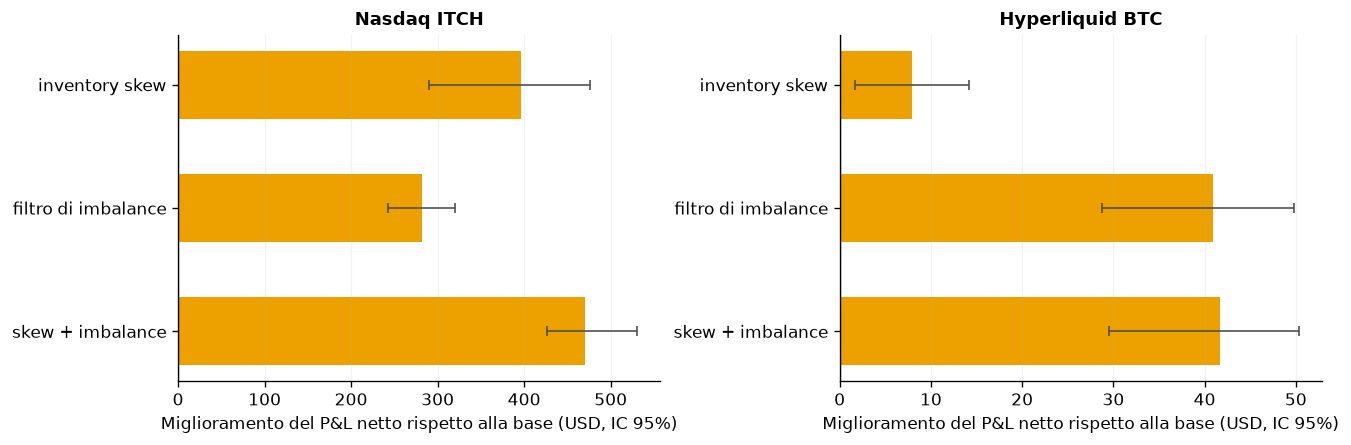

*Figura.* Differenza di P&L netto tra ogni variante e la strategia base, sulle stesse sessioni di test. Tutte le varianti riducono la perdita, ma il P&L netto resta negativo. La variante migliore su ITCH (skew + imbalance) passa da -70,75 USD senza latenza a -138,87 con 1 ms e -149,35 con 100 ms. *Limite:* le varianti sono state introdotte dopo aver visto i risultati e il loro vantaggio dipende da cancellazioni istantanee.

In [8]:
tables = []
for name, ref, fee in [("itch", "queue", "fees_nasdaq_base"), ("hyperliquid", "queue", "fees_tier0"),
                       ("fi2010", "price-through", None)]:
    eff = R.variant_effect(test, variants, name, NET[name], model=ref, fee_column=fee)
    eff.assign(dataset=R.DATASET_LABELS[name]).to_csv(ROOT / "results" / "tabella_varianti.csv",
                                                      mode="a" if tables else "w", header=not tables)
    table = R.variants_table(eff, 4 if name == "fi2010" else 2)
    table.index = pd.MultiIndex.from_product([[R.DATASET_LABELS[name]], table.index])
    tables.append(table)
display(pd.concat(tables))
vstress = R.load(ROOT, "variants_stress").query("dataset == 'itch'")
latency = vstress.groupby("param_latency_ns").net_nasdaq_base.mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for ax, name in zip(axes, ["itch", "hyperliquid"]):
    eff = R.variant_effect(test, variants, name, NET[name], fee_column="fees_nasdaq_base" if name == "itch" else "fees_tier0").drop(index="base")
    y = np.arange(len(eff))[::-1]
    ax.barh(y, eff["differenza vs base"], color=R.COLORS["queue"], height=0.55)
    ax.errorbar(eff["differenza vs base"], y, xerr=[eff["differenza vs base"] - eff["diff IC95 basso"],
                eff["diff IC95 alto"] - eff["differenza vs base"]], fmt="none", ecolor=R.INK, capsize=3, linewidth=1)
    ax.set_yticks(y, eff.index)
    ax.axvline(0, color=R.INK, linewidth=0.8)
    ax.set(title=R.DATASET_LABELS[name], xlabel="Miglioramento del P&L netto rispetto alla base (USD, IC 95%)")
    ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "varianti_strategia.png", dpi=180, bbox_inches="tight")
plt.show()
R.caption("Differenza di P&L netto tra ogni variante e la strategia base, sulle stesse sessioni di test.",
          f"Tutte le varianti riducono la perdita, ma il P&L netto resta negativo. La variante migliore su ITCH "
          f"({R.VARIANT_LABELS[vstress.variant.iloc[0]]}) passa da {it(latency.iloc[0], 2)} USD senza latenza a "
          f"{it(latency.iloc[1], 2)} con 1 ms e {it(latency.iloc[-1], 2)} con 100 ms.",
          "le varianti sono state introdotte dopo aver visto i risultati e il loro vantaggio dipende da cancellazioni istantanee.")

## 10. Limiti

* **Campione:** 5 giornate di test ITCH (le uniche pubblicate gratuitamente dal Nasdaq), 4 ore Hyperliquid, 7 giornate FI-2010; poche sessioni indipendenti rendono gli intervalli approssimati.
* **Overfitting:** una sola sessione di validazione per ITCH e Hyperliquid.
* **Replay della coda:** gli ordini simulati non modificano il mercato (nessun market impact); gli ordini nascosti e gli scambi su altre borse non sono considerati.
* **Hyperliquid:** dati senza orari; durata e latenza in eventi; classificazione delle esecuzioni approssimata quando un ordine ha più riduzioni.
* **FI-2010:** prezzi normalizzati, nessuna coda, confini tra titoli individuati in modo euristico.
* **Costi e latenza:** tariffe indicative da verificare; latenza costante.
* **Varianti:** esplorative, introdotte dopo l'osservazione dei risultati.

## 11. Risposta alla domanda di ricerca

In [9]:
criteria = []
for name in ["itch", "hyperliquid"]:
    g = test[(test.dataset == name) & (test.model == "queue")]
    limit = {"itch": 100, "hyperliquid": 0.01}[name]
    mean, low, high = grouped_bootstrap_ci(g[NET[name]], g.session)
    criteria.append({"dataset": R.DATASET_LABELS[name],
                     "P&L netto medio con la coda (IC 95% per sessione)": R.ci_text(mean, low, high, 2),
                     "titolo-sessioni positive": pct((g[NET[name]] > 0).mean(), 0),
                     "inventario entro il limite": "sì" if (g.max_abs_inventory_seen <= limit + 1e-9).all() else "no"})
display(pd.DataFrame(criteria).set_index("dataset"))
display(Markdown("""
**Conclusione.** Nei campioni analizzati, la strategia non conserva una profittabilità netta positiva quando
l'esecuzione viene simulata tramite la posizione nella coda. Il modello L2 `touch` sovrastima fortemente i fill. Il
filtro di volatilità e le varianti di gestione dell'inventario riducono le perdite, ma non modificano la conclusione
principale. I risultati mostrano quindi che la granularità dei dati e il modello di esecuzione sono determinanti
nella valutazione di una strategia di market making.
"""))

,P&L netto medio con la coda (IC 95% per sessione),titolo-sessioni positive,inventario entro il limite
dataset,,,
Nasdaq ITCH,"-540,59 (-580,70; -500,47)",0%,sì
Hyperliquid BTC,"-47,28 (-56,71; -34,16)",0%,sì



**Conclusione.** Nei campioni analizzati, la strategia non conserva una profittabilità netta positiva quando
l'esecuzione viene simulata tramite la posizione nella coda. Il modello L2 `touch` sovrastima fortemente i fill. Il
filtro di volatilità e le varianti di gestione dell'inventario riducono le perdite, ma non modificano la conclusione
principale. I risultati mostrano quindi che la granularità dei dati e il modello di esecuzione sono determinanti
nella valutazione di una strategia di market making.


## 12. Glossario

| Termine | Significato |
|---|---|
| **Limit order book (LOB)** | Elenco degli ordini di acquisto e vendita in attesa su uno strumento, ordinati per prezzo. |
| **Bid** | Prezzo a cui qualcuno è disposto a comprare; il *best bid* è il più alto. |
| **Ask** | Prezzo a cui qualcuno è disposto a vendere; il *best ask* è il più basso. |
| **Spread** | Differenza tra best ask e best bid: il guadagno massimo di un market maker su una coppia di ordini. |
| **Tick** | Passo minimo di prezzo (1 centesimo per le azioni Nasdaq, 1 USD per BTC su Hyperliquid). |
| **Midpoint** | Media tra best bid e best ask; usato come prezzo di riferimento. |
| **L1, L2, L3, L4** | Livelli di dettaglio dei dati: L1 solo i prezzi migliori; L2 prezzi e volumi aggregati per livello; L3 ogni singolo ordine (*market by order*); L4 ogni ordine con l'identità di chi lo ha inserito. |
| **Market maker** | Operatore che inserisce ordini su entrambi i lati del book e guadagna sullo spread, fornendo liquidità. |
| **Quota** | Ordine passivo del market maker (qui una coppia: uno in acquisto e uno in vendita). |
| **Maker / taker** | Chi fornisce liquidità con un ordine che resta nel book / chi la prende con un ordine eseguito subito. |
| **Fill (esecuzione)** | Esecuzione, totale o parziale, di un ordine. |
| **Fill rate** | Quota delle quote inserite che viene eseguita almeno in parte. |
| **Coda FIFO** | A parità di prezzo viene eseguito prima l'ordine inserito prima (*first in, first out*, priorità prezzo-tempo). |
| **Posizione in coda** | Quanto volume c'è davanti al proprio ordine allo stesso prezzo. |
| **touch, price-through, cross** | Regole che deducono le esecuzioni dai soli prezzi L2 (notebook 02); `touch` è un limite superiore ottimistico. |
| **Replay order-level** | Simulazione che rigioca il flusso storico degli ordini e mette la quota nella coda reale (notebook 04). |
| **Inventario** | Quantità dello strumento posseduta (positiva) o venduta allo scoperto (negativa). |
| **Liquidazione** | Chiusura dell'inventario con un ordine a mercato. |
| **Mark-to-market** | Valutazione dell'inventario al prezzo corrente (qui il midpoint). |
| **Equity** | Valore del conto: cassa più inventario valutato mark-to-market. |
| **Volatilità** | Ampiezza dei movimenti del prezzo; qui deviazione standard dei rendimenti del midpoint su una finestra mobile. |
| **Selezione avversa (adverse selection)** | Tendenza a essere eseguiti proprio quando il prezzo sta per muoversi contro (Glosten e Milgrom, 1985). |
| **Markout** | Variazione del midpoint in un intervallo dopo un'esecuzione; misura la selezione avversa. |
| **Edge maker** | Guadagno di un'esecuzione rispetto al midpoint del momento. |
| **Latenza** | Ritardo tra la decisione e l'arrivo di un ordine o di una cancellazione sul mercato. |
| **Post-only** | Ordine rifiutato se verrebbe eseguito subito: garantisce di restare maker. |
| **P&L lordo / netto** | Profitto o perdita prima / dopo commissioni e rebate. |
| **Commissione, rebate** | Costo pagato all'exchange per ogni scambio; il rebate è un compenso a chi fornisce liquidità. |
| **Turnover** | Controvalore totale scambiato. |
| **Drawdown** | Massima perdita dal punto più alto della curva di equity. |
| **Imbalance** | (volume in acquisto − volume in vendita) / somma al miglior prezzo; anticipa la direzione del prezzo a brevissimo termine (Cont, Kukanov e Stoikov, 2014). |
| **Inventory skew** | Spostamento delle quote in funzione dell'inventario (Avellaneda e Stoikov, 2008); qui una variante esplorativa. |
| **Sessione, titolo-sessione** | Sessione: una giornata (FI-2010, ITCH) o un'ora (Hyperliquid); titolo-sessione: un titolo in una sessione. |
| **Calibrazione, validazione, test** | Divisione cronologica dei dati: stimare le soglie, scegliere i parametri, misurare il risultato senza più modificarli. |
| **Ablazione** | Ripetere l'esperimento togliendo un componente per misurarne il contributo. |
| **Bootstrap** | Stima dell'incertezza ricampionando i dati (Efron e Tibshirani, 1993); qui si ricampionano sessioni intere. |
| **Intervallo di confidenza (IC 95%)** | Intervallo che, con il 95% di confidenza, contiene il valore medio vero. |
| **Overfitting** | Scelta di parametri che funzionano sui dati usati per sceglierli ma non su dati nuovi. |
| **ITCH, FI-2010, book diff** | Flusso ordine per ordine del Nasdaq; dataset accademico L2 normalizzato; modifica elementare del book nei dati Hyperliquid. |

## 13. Fonti

**Modelli di market making e rischio di inventario**

- Ho, T., Stoll, H. R. (1981). Optimal dealer pricing under transactions and return uncertainty. *Journal of Financial Economics*, 9(1), 47-73.
- Avellaneda, M., Stoikov, S. (2008). High-frequency trading in a limit order book. *Quantitative Finance*, 8(3), 217-224.
- Guéant, O., Lehalle, C.-A., Fernandez-Tapia, J. (2013). Dealing with the inventory risk: a solution to the market making problem. *Mathematics and Financial Economics*, 7(4), 477-507.
- Cartea, Á., Jaimungal, S., Penalva, J. (2015). *Algorithmic and High-Frequency Trading*. Cambridge University Press.

**Microstruttura, coda e selezione avversa**

- Glosten, L. R., Milgrom, P. R. (1985). Bid, ask and transaction prices in a specialist market with heterogeneously informed traders. *Journal of Financial Economics*, 14(1), 71-100.
- Cont, R., Stoikov, S., Talreja, R. (2010). A stochastic model for order book dynamics. *Operations Research*, 58(3), 549-563.
- Huang, W., Lehalle, C.-A., Rosenbaum, M. (2015). Simulating and analyzing order book data: the queue-reactive model. *Journal of the American Statistical Association*, 110(509), 107-122.
- Moallemi, C. C., Yuan, K. (2017). A model for queue position valuation in a limit order book. Working paper, Columbia University.
- Gould, M. D., Porter, M. A., Williams, S., McDonald, M., Fenn, D. J., Howison, S. D. (2013). Limit order books. *Quantitative Finance*, 13(11), 1709-1742.
- Bouchaud, J.-P., Bonart, J., Donier, J., Gould, M. (2018). *Trades, Quotes and Prices: Financial Markets Under the Microscope*. Cambridge University Press.

**Segnali del book, velocità e market maker reali**

- Cont, R., Kukanov, A., Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics*, 12(1), 47-88.
- Cartea, Á., Donnelly, R., Jaimungal, S. (2018). Enhancing trading strategies with order book signals. *Applied Mathematical Finance*, 25(1), 1-35.
- Hasbrouck, J., Saar, G. (2013). Low-latency trading. *Journal of Financial Markets*, 16(4), 646-679.
- Menkveld, A. J. (2013). High frequency trading and the new market makers. *Journal of Financial Markets*, 16(4), 712-740.
- Budish, E., Cramton, P., Shim, J. (2015). The high-frequency trading arms race: frequent batch auctions as a market design response. *Quarterly Journal of Economics*, 130(4), 1547-1621.

**Metodologia**

- Bailey, D. H., Borwein, J. M., López de Prado, M., Zhu, Q. J. (2017). The probability of backtest overfitting. *Journal of Computational Finance*, 20(4), 39-69.
- Efron, B., Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.

**Dati**

- Ntakaris, A., Magris, M., Kanniainen, J., Gabbouj, M., Iosifidis, A. (2018). Benchmark dataset for mid-price forecasting of limit order book data with machine learning methods. *Journal of Forecasting*, 37(8), 852-866.
- Nasdaq. *Nasdaq TotalView-ITCH 5.0* (specifica del protocollo e file campione pubblici).
- Albers, J., Cucuringu, M., Howison, S., Shestopaloff, A. Y. (2026). An Open Book: Level 4 Order Book Data from the Hyperliquid Exchange. Zenodo, doi:10.5281/zenodo.18184441.